# 07 · Post-Training Diffusion Models: Adaptation and Reward Alignment

## Overview

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| 01 | Pretraining | Next-token prediction on raw text | Knowledge: the model *can* add | Doesn't follow instructions |
| 02 | SFT + LoRA | Imitate demonstrations | Follows the chat format | Copies demonstrators' mistakes; forgets |
| 03 | Reward model + PPO | Learn a reward from preferences, optimise it | Can go beyond imitation | Reward hacking; four models; fragile |
| 04 | DPO family | Optimise preferences directly, no RL loop | Simple and stable | Offline: only re-weights existing behaviour |
| 05 | GRPO / RLVR | Online RL against a verifier | Verifiable gains, no value network | Sharpens, rarely expands; needs a capable start |
| 06 | Diffusion | Learn to denoise | Stable, high-quality generation | Matches data, not *goals*; slow sampling |
| **07** | **Diffusion post-training** | **Fine-tune and reward-align a denoiser** | **Steer generation to a goal** | **Reward hacking again; still slow** |
| 08 | Distillation | Few-step students | 10-100x faster sampling | Small denoisers don't scale |
| 09 | Diffusion transformers | Tokens + adaLN + flow matching | Scalable, flexible conditioning | Needs post-training too |
| 10 | Capstone | GRPO and DPO on a DiT; diffusion LMs | Unifies both threads | → the research frontier |

Notebook 06 ended with a diffusion model that reproduces its data faithfully, and can do nothing else. Asked for
**bold** digits, it can only offer the boldness of its training set. This notebook ports the language-model
post-training toolbox to denoisers, in two parts.

**Part A, adaptation** (the diffusion counterpart of SFT and LoRA, notebook 02). Teach the model a new concept from
20 examples: DreamBooth ([Ruiz et al., 2022](https://arxiv.org/abs/2208.12242)), textual inversion ([Gal et al., 2022](https://arxiv.org/abs/2208.01618)) and LoRA ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)).

**Part B, reward alignment** (the counterpart of notebooks 03-05). Optimise a reward directly:

| Language models | Diffusion models | Idea |
|---|---|---|
| PPO on a reward (NB03) | **DDPO** ([Black et al., 2023](https://arxiv.org/abs/2305.13301)), DPOK ([Fan et al., 2023](https://arxiv.org/abs/2305.16381)) | each denoising step is an action; policy gradient over the chain |
| *(no direct analogue)* | **DRaFT** ([Clark et al., 2023](https://arxiv.org/abs/2309.17400)), AlignProp ([Prabhudesai et al., 2023](https://arxiv.org/abs/2310.03739)), ReFL ([Xu et al., 2023](https://arxiv.org/abs/2304.05977)) | the sampler is differentiable: back-propagate the reward through it |
| DPO (NB04) | **Diffusion-DPO** ([Wallace et al., 2023](https://arxiv.org/abs/2311.12908)) | DPO with log-likelihoods replaced by denoising errors |
| KL penalty (NB03) | DPOK's per-step KL | stay close to the pretrained model |

The reward is deliberately simple: the **amount of ink** in the image. Two evaluators we never optimise against
tell us whether the images are still digits: the CNN judge, and a pixel-space k-nearest-neighbour classifier with
a very different inductive bias. The kNN plays the role of a held-out human evaluation.

## Learning objectives

1. Adapt a diffusion model to a new concept from 20 images, and measure the overfitting and drift each method causes.
2. Write the denoising chain as an MDP and implement DDPO; implement DRaFT by back-propagating through the sampler.
3. Derive and implement Diffusion-DPO.
4. Measure **reward hacking** in image space, including a reward model being fooled, and the effect of KL regularisation.

**Runtime:** about 10 minutes on a laptop CPU.

In [1]:
import sys, time, copy, inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
sys.path.insert(0, ".")
from ptlib import images, metrics, set_seed
from ptlib import diffusion as dfx
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
Xtr, ytr, Xte, yte = images.load_digits_tensor()
base = dfx.get_base_diffusion()                  # notebook 06's v-prediction model
judge = images.get_judge()
knn = images.PixelKNN()
sc = metrics.ImageScorecard(judge, Xtr, Xte, yte)
sc_bold = metrics.ImageScorecard(judge, images.bold(Xtr), images.bold(Xte), yte)     # the 'bold digits' target distribution
print(f"held-out kNN accuracy: normal digits {knn.accuracy(Xte, yte):.3f}, bold digits {knn.accuracy(images.bold(Xte), yte):.3f}")

@torch.no_grad()
def evaluate(model, name=None, steps=20, labels=yte, seed=123):
    set_seed(seed); s = dfx.sample_ddim(model, labels, steps=steps)
    f = judge.features(s).numpy()
    r = dict(ink=dfx.ink(s).mean().item(), judge_acc=(judge(s).argmax(1) == labels).float().mean().item(),
             knn_acc=knn.accuracy(s, labels), fd_to_bold=metrics._frechet(sc_bold.f_te, f), fd_to_data=metrics._frechet(sc.f_te, f),
             diversity=torch.pdist(s).mean().item())
    return (r, s) if name else r
base_eval = evaluate(base)
print("base model:", {k: round(v, 3) for k, v in base_eval.items()})
print(f"real bold digits: ink {dfx.ink(images.bold(Xte)).mean():.3f}")

held-out kNN accuracy: normal digits 0.983, bold digits 0.891
base model: {'ink': 0.306, 'judge_acc': 0.994, 'knn_acc': 1.0, 'fd_to_bold': 256.332, 'fd_to_data': 5.823, 'diversity': 5.549}
real bold digits: ink 0.703


# Part A · Adaptation

## 1. Teaching a new concept from 20 images

DreamBooth ([Ruiz et al., 2022](https://arxiv.org/abs/2208.12242)) binds a new subject to a **rare identifier token**, "a [V] dog", by fine-tuning the
whole model on 3-5 photos. Our version: add a new label, `11 = "bold three"`, whose embedding is initialised from
the class `3`, and fine-tune on **20 bold threes** (strokes thickened by a 3×3 max filter). Four methods:

* **full fine-tuning**: every weight is trained;
* **DreamBooth with prior preservation**: also train on images the *original* model generates for all ten classes, so the rest of the model is anchored where it was;
* **textual inversion** ([Gal et al., 2022](https://arxiv.org/abs/2208.01618)): freeze the network and train only the new label's embedding;
* **LoRA** ([Hu et al., 2021](https://arxiv.org/abs/2106.09685)): rank-4 adapters on every linear layer of the denoiser, as in notebook 02.

In [2]:
NEW = 11
bold3 = images.bold(Xtr[ytr == 3][:20])
y_new = torch.full((20,), NEW)
set_seed(0); prior_y = torch.arange(10).repeat(40); prior_X = dfx.sample_ddim(base, prior_y, steps=50)

adapted = {}
adapted["full fine-tuning"] = dfx.finetune(dfx.add_class_token(base), bold3, y_new)
adapted["DreamBooth (+ prior preservation)"] = dfx.finetune(dfx.add_class_token(base), bold3, y_new, prior=(prior_X, prior_y))
ti = dfx.add_class_token(base)
for p in ti.parameters(): p.requires_grad_(False)
ti.cemb.weight.requires_grad_(True)
adapted["textual inversion"] = dfx.finetune(ti, bold3, y_new, lr=1e-2)
lo = dfx.add_lora_denoiser(dfx.add_class_token(base), r=4); lo.cemb.weight.requires_grad_(True)
adapted["LoRA r=4 (+ new embedding)"] = dfx.finetune(lo, bold3, y_new, lr=2e-3)

rows = {}
for name, m in adapted.items():
    set_seed(0); s_new = dfx.sample_ddim(m, torch.full((100,), NEW), steps=50)
    set_seed(0); s_3 = dfx.sample_ddim(m, torch.full((100,), 3), steps=50)
    others = evaluate(m)
    rows[name] = {"new token: ink": dfx.ink(s_new).mean().item(), "new token: judged a 3": (judge(s_new).argmax(1) == 3).float().mean().item(),
                  "new token: diversity": torch.pdist(s_new).mean().item(), "plain '3': ink (drift)": dfx.ink(s_3).mean().item(),
                  "all classes: FD to data (drift)": others["fd_to_data"], "all classes: kNN acc": others["knn_acc"],
                  "trainable params": sum(p.numel() for p in m.parameters() if p.requires_grad)}
    adapted[name] = (m, s_new, s_3)
ref_row = {"new token: ink": dfx.ink(bold3).mean().item(), "new token: judged a 3": (judge(bold3).argmax(1) == 3).float().mean().item(),
           "new token: diversity": torch.pdist(bold3).mean().item(), "plain '3': ink (drift)": dfx.ink(Xtr[ytr == 3]).mean().item(),
           "all classes: FD to data (drift)": base_eval["fd_to_data"], "all classes: kNN acc": base_eval["knn_acc"]}
display(pd.DataFrame({"the 20 training images / base model": ref_row, **rows}).T.round(3))

,new token: ink,new token: judged a 3,new token: diversity,plain '3': ink (drift),all classes: FD to data (drift),all classes: kNN acc,trainable params
the 20 training images / base model,0.708,0.45,4.032,0.300,5.823,1.000,NaN
full fine-tuning,0.694,0.76,2.728,0.695,230.345,0.460,1452352.0
DreamBooth (+ prior preservation),0.668,0.80,2.826,0.642,29.697,1.000,1452352.0
textual inversion,0.469,0.30,4.861,0.300,5.823,1.000,3072.0
LoRA r=4 (+ new embedding),0.680,0.81,2.710,0.681,232.748,0.345,35840.0


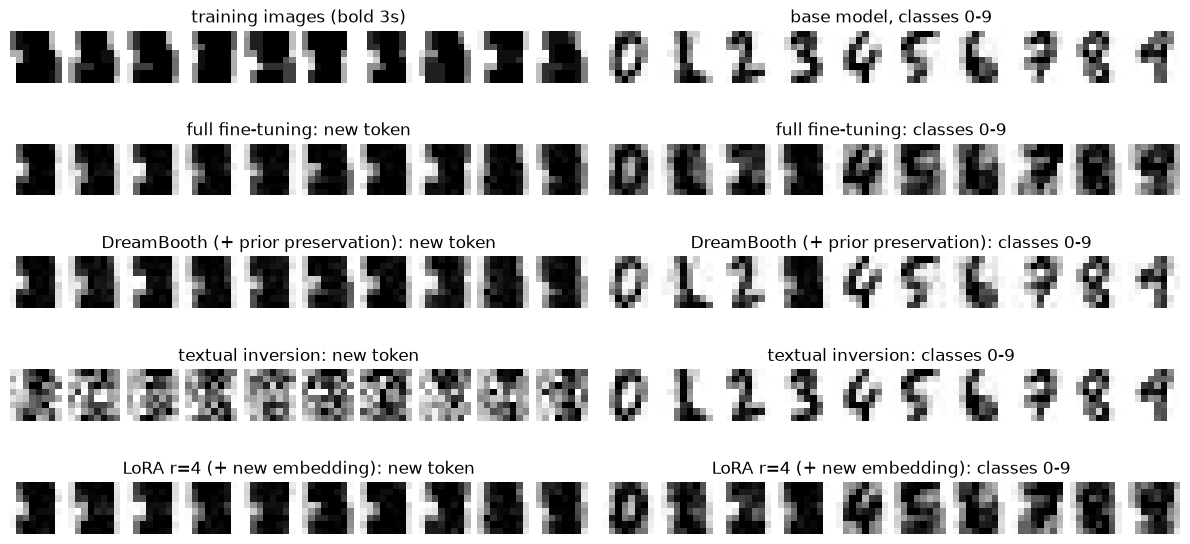

In [3]:
fig, axes = plt.subplots(len(adapted) + 1, 2, figsize=(12, 1.2 * (len(adapted) + 1)))
images.show_grid(bold3[:10], nrow=10, ax=axes[0, 0], title="training images (bold 3s)")
set_seed(0); images.show_grid(dfx.sample_ddim(base, torch.arange(10), steps=50), nrow=10, ax=axes[0, 1], title="base model, classes 0-9")
for i, (name, (m, s_new, s_3)) in enumerate(adapted.items(), 1):
    images.show_grid(s_new[:10], nrow=10, ax=axes[i, 0], title=f"{name}: new token")
    set_seed(0); images.show_grid(dfx.sample_ddim(m, torch.arange(10), steps=50), nrow=10, ax=axes[i, 1], title=f"{name}: classes 0-9")
fig.tight_layout(); plt.show()

**Reading Part A.** The same trade-off as SFT and LoRA in notebook 02 appears, more visibly:

* **Full fine-tuning** learns the new concept and wrecks everything else. Twenty images for 400 steps, with nothing anchoring the other labels, is enough to drag the shared weights toward "bold three". Check the drift columns: the plain `3` gets bold, and the FD of all classes explodes. DreamBooth calls this *language drift*.
* **Prior preservation** anchors the other classes with the original model's own samples. Drift is much smaller (but not zero) and the new concept is still learned.
* **Textual inversion** cannot drift: only one embedding vector is trained. But a 256-number embedding cannot fully express "thick strokes" through a frozen network, so it captures the concept only partly.
* **LoRA does not protect against drift here.** It trains 2.5% of the parameters, yet it drifts about as badly as full fine-tuning: the plain `3` turns bold and the other classes degrade. Low rank limits *how much* the model can change, not *where* the change applies. Every label passes through the same adapted weights, and 400 steps on one concept is enough to move all of them. In notebook 02 LoRA forgot less because its learning signal was spread over a whole task; here it is concentrated on 20 images. Only prior preservation, which supplies data for what should *not* change, targets drift directly.

ControlNet ([Zhang et al., 2023](https://arxiv.org/abs/2302.05543)) is the same idea applied to *conditioning*. It adds a trainable copy of the encoder,
connected through zero-initialised layers (like LoRA's $B = 0$), so new inputs such as edges or poses can be
attached without disturbing the pretrained model.

# Part B · Reward alignment

## 2. Denoising as a decision process

A stochastic sampler with $K$ steps (here DDIM with $\eta = 1$, $K = 20$) defines a chain $x_{t_K} \to \dots \to x_{t_0}$
in which **every transition is a Gaussian**: $p_\theta(x_{s}\mid x_t) = \mathcal{N}(\mu_\theta(x_t, t), \sigma_t^2 I)$. Treat each step as an
action, with the reward $r(x_0)$ given only at the end. This is an MDP, and the policy gradient of notebook 05 applies:
$$\nabla_\theta J = \mathbb{E}\Big[\, r(x_0) \sum_k \nabla_\theta \log p_\theta(x_{t_{k-1}} \mid x_{t_k}) \Big].$$

**DDPO** ([Black et al., 2023](https://arxiv.org/abs/2305.13301)) uses this with PPO's clipped importance ratio and batch-normalised rewards. Unlike the
language case, we can also **differentiate the sample itself** with respect to $\theta$, because a deterministic
DDIM sample is a differentiable function of the noise. **DRaFT** ([Clark et al., 2023](https://arxiv.org/abs/2309.17400)) back-propagates $\nabla_x r$ through
the last $K$ sampling steps (here $K = 1$), which is cheaper and needs no variance reduction.

In [4]:
src = inspect.getsource(dfx.ddpo)
print(src[src.index("    for it in range(iters):"):src.index("        row = dict(")])
reward = lambda x, c: dfx.ink(x)
eval_fn = lambda m: evaluate(m)
runs, models = {}, {}
t0 = time.time()
models["DDPO"], runs["DDPO"] = dfx.ddpo(copy.deepcopy(base), reward, iters=300, lr=1e-4, eval_fn=eval_fn, log_every=50)
print(f"DDPO: {time.time() - t0:.0f}s")
t0 = time.time()
models["DRaFT-1"], runs["DRaFT-1"] = dfx.draft(copy.deepcopy(base), reward, iters=600, lr=2e-5, eval_fn=eval_fn, log_every=100)
print(f"DRaFT-1: {time.time() - t0:.0f}s")

    for it in range(iters):
        model.eval()
        labels = random_labels(batch)
        x0, traj = sample_with_logprob(model, labels, steps=steps)
        r = reward_fn(x0, labels)
        adv = ((r - r.mean()) / (r.std() + 1e-6)).detach()
        with torch.no_grad():
            old = [gaussian_logprob(xn, *ddim_step_mean(model, x, tt, s, labels)) for x, tt, s, xn in traj]
        model.train()
        for _ in range(inner):
            for k, (x, tt, s, xn) in enumerate(traj):
                mean, sigma = ddim_step_mean(model, x, tt, s, labels)
                lp = gaussian_logprob(xn, mean, sigma)
                ratio = torch.exp(lp - old[k])
                loss = -torch.min(ratio * adv, ratio.clamp(1 - clip, 1 + clip) * adv).mean()
                if kl_coef > 0:
                    with torch.no_grad():
                        mean_ref, _ = ddim_step_mean(ref, x, tt, s, labels)
                    loss = loss + kl_coef * (((mean - mean_ref) ** 2).sum(-1) / (2 * sigma[:,

## 3. Diffusion-DPO

[Wallace et al., 2023](https://arxiv.org/abs/2311.12908) apply notebook 04's derivation to diffusion. The sequence log-likelihood $\log\pi_\theta(y\mid x)$ is
intractable for a diffusion model, but its ELBO is a sum of denoising errors. Replacing log-ratios by
differences in denoising error, evaluated at a shared timestep and noise, gives
$$\mathcal{L} = -\log\sigma\Big(-\beta\,\big[(\|e_\theta(x^w_t)\|^2 - \|e_\text{ref}(x^w_t)\|^2) - (\|e_\theta(x^l_t)\|^2 - \|e_\text{ref}(x^l_t)\|^2)\big]\Big),$$
where $e(x_t) = v_\theta(x_t, t) - v$ is the prediction error. In words: **become better than the reference at
denoising the preferred image, relative to the rejected one.** The preference pairs are two base-model samples
of the same class; the one with more ink wins. This is offline, like DPO: the model never sees its own samples
during training.

In [5]:
set_seed(1)
pair_y = torch.randint(0, 10, (4000,))
a, b = dfx.sample_ddim(base, pair_y, steps=20), dfx.sample_ddim(base, pair_y, steps=20)
a_wins = (dfx.ink(a) > dfx.ink(b))[:, None]
x_w, x_l = torch.where(a_wins, a, b), torch.where(a_wins, b, a)
print(f"{len(pair_y)} pairs; mean ink chosen {dfx.ink(x_w).mean():.3f} vs rejected {dfx.ink(x_l).mean():.3f}")
t0 = time.time()
models["Diffusion-DPO"], runs["Diffusion-DPO"] = dfx.diffusion_dpo(copy.deepcopy(base), base, x_w, x_l, pair_y, iters=800, beta=5000, lr=1e-4,
                                                                   eval_fn=eval_fn, log_every=200)
print(f"Diffusion-DPO: {time.time() - t0:.0f}s")

4000 pairs; mean ink chosen 0.323 vs rejected 0.292
{'iter': 200, 'loss': 18.524, 'ink': 0.336, 'judge_acc': 0.989, 'knn_acc': 0.997, 'fd_to_bold': 243.328, 'fd_to_data': 7.661, 'diversity': 5.548}
{'iter': 400, 'loss': 9.386, 'ink': 0.346, 'judge_acc': 0.989, 'knn_acc': 0.997, 'fd_to_bold': 238.571, 'fd_to_data': 10.097, 'diversity': 5.532}
{'iter': 600, 'loss': 2.337, 'ink': 0.353, 'judge_acc': 0.992, 'knn_acc': 0.997, 'fd_to_bold': 235.716, 'fd_to_data': 9.883, 'diversity': 5.518}
{'iter': 800, 'loss': 1.713, 'ink': 0.357, 'judge_acc': 0.992, 'knn_acc': 0.997, 'fd_to_bold': 220.862, 'fd_to_data': 12.529, 'diversity': 5.469}
Diffusion-DPO: 34s


,ink,judge_acc,knn_acc,fd_to_bold,fd_to_data,diversity
base,0.306,0.994,1.000,256.332,5.823,5.549
DDPO,0.683,0.354,0.220,102.277,321.400,3.308
DRaFT-1,0.684,0.206,0.114,298.265,510.205,4.136
Diffusion-DPO,0.357,0.992,0.997,220.862,12.529,5.469


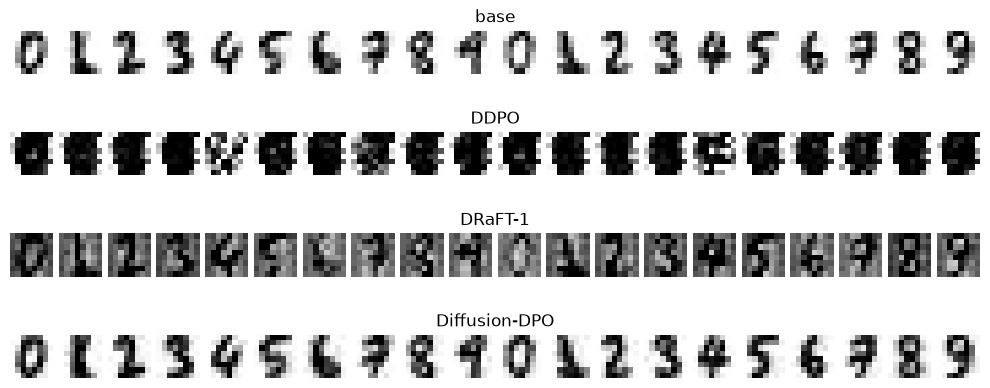

In [6]:
table = pd.DataFrame({"base": base_eval, **{k: evaluate(m) for k, m in models.items()}}).T
display(table.round(3))
fig, axes = plt.subplots(len(models) + 1, 1, figsize=(10, 1.1 * (len(models) + 1)))
set_seed(0); images.show_grid(dfx.sample_ddim(base, torch.arange(10).repeat(2), steps=20), nrow=20, ax=axes[0], title="base")
for ax, (name, m) in zip(axes[1:], models.items()):
    set_seed(0); images.show_grid(dfx.sample_ddim(m, torch.arange(10).repeat(2), steps=20), nrow=20, ax=ax, title=name)
fig.tight_layout(); plt.show()

**Reading the three methods.** All three were given the same goal, more ink, and the table and grid show how
differently they reached it.

* **DDPO** finds the simplest high-reward image: a **blob**. Ink goes up, and both held-out classifiers fall toward chance. The images are no longer digits. This is notebook 03's $\beta = 0$ collapse in pixel space.
* **DRaFT** hacks the reward in a different way. Its gradient points along the cheapest direction to add ink, a uniform shift of every pixel, so its samples develop a **grey background**. Gradient-based alignment is extremely sample-efficient, and so it is also efficient at finding reward bugs.
* **Diffusion-DPO** moves only a little: slightly bolder, still clearly digits. Like DPO in notebook 04, it can only re-weight what is in its offline pairs, whose ink gap is small. Here that conservatism is the safety margin.

None of them produces what we *meant*, bold digits (compare `fd_to_bold` with the base row). The reward does
not say "and still a digit". The obvious fix is to add that to the reward.

## 4. Fixing the reward: add a classifier term

Text-to-image alignment usually mixes rewards: an aesthetic score plus a prompt-alignment score (CLIP or a learned
preference model; [Xu et al., 2023](https://arxiv.org/abs/2304.05977), [Lee et al., 2023](https://arxiv.org/abs/2302.12192)). Our version adds $0.05 \log p_\text{judge}(c \mid x)$, "and it must still look
like the requested digit", and keeps the kNN as the held-out check.

In [7]:
reward_mix = lambda x, c: dfx.ink(x) + 0.05 * F.log_softmax(judge(x), -1)[torch.arange(len(c)), c]
t0 = time.time()
models["DDPO, ink + judge"], runs["DDPO, ink + judge"] = dfx.ddpo(copy.deepcopy(base), reward_mix, iters=300, lr=1e-4, eval_fn=eval_fn, log_every=100)
print(f"{time.time() - t0:.0f}s")
r = evaluate(models["DDPO, ink + judge"])
print(f"judge accuracy {r['judge_acc']:.3f}  vs  held-out kNN accuracy {r['knn_acc']:.3f}")

{'iter': 100, 'reward': 0.552, 'ink': 0.544, 'judge_acc': 0.916, 'knn_acc': 0.398, 'fd_to_bold': 86.456, 'fd_to_data': 120.124, 'diversity': 4.385}
{'iter': 200, 'reward': 0.639, 'ink': 0.637, 'judge_acc': 0.911, 'knn_acc': 0.365, 'fd_to_bold': 54.182, 'fd_to_data': 213.394, 'diversity': 3.579}
{'iter': 300, 'reward': 0.621, 'ink': 0.621, 'judge_acc': 0.88, 'knn_acc': 0.549, 'fd_to_bold': 65.867, 'fd_to_data': 223.49, 'diversity': 3.875}
159s
judge accuracy 0.880  vs  held-out kNN accuracy 0.549


The judge now *says* the images are the requested digits, but the held-out kNN disagrees, and the images
(grid below) are still mostly blobs. Once the judge is part of the reward, it stops being an independent
evaluator: the policy finds images that the CNN classifies as digits but that are not digits. This is the
**adversarial example** version of reward-model overoptimisation (notebook 03). It is the reason labs evaluate
aligned image models with held-out human raters, not with the reward models they trained against.

## 5. Fixing the optimiser: a KL penalty (DPOK)

DPOK ([Fan et al., 2023](https://arxiv.org/abs/2305.16381)) adds the KL between the fine-tuned and pretrained transition distributions to DDPO. Both are
Gaussians with the same variance, so the per-step KL is simply $\|\mu_\theta - \mu_\text{ref}\|^2 / 2\sigma_t^2$. We sweep
its coefficient on the plain ink reward.

In [8]:
for kl in [0.01, 0.1]:
    name = f"DPOK (DDPO + KL {kl:g})"
    t0 = time.time()
    models[name], runs[name] = dfx.ddpo(copy.deepcopy(base), reward, iters=300, lr=1e-4, kl_coef=kl, ref=base, eval_fn=eval_fn, log_every=100)
    print(f"{name}: {time.time() - t0:.0f}s", {k: round(v, 3) for k, v in evaluate(models[name]).items()})

{'iter': 100, 'reward': 0.486, 'ink': 0.478, 'judge_acc': 0.763, 'knn_acc': 0.487, 'fd_to_bold': 93.273, 'fd_to_data': 131.345, 'diversity': 4.213}
{'iter': 200, 'reward': 0.552, 'ink': 0.562, 'judge_acc': 0.404, 'knn_acc': 0.301, 'fd_to_bold': 74.02, 'fd_to_data': 263.027, 'diversity': 3.339}
{'iter': 300, 'reward': 0.573, 'ink': 0.592, 'judge_acc': 0.279, 'knn_acc': 0.17, 'fd_to_bold': 70.183, 'fd_to_data': 348.686, 'diversity': 2.917}
DPOK (DDPO + KL 0.01): 162s {'ink': 0.592, 'judge_acc': 0.279, 'knn_acc': 0.17, 'fd_to_bold': 70.183, 'fd_to_data': 348.686, 'diversity': 2.917}
{'iter': 100, 'reward': 0.371, 'ink': 0.366, 'judge_acc': 0.994, 'knn_acc': 0.983, 'fd_to_bold': 247.575, 'fd_to_data': 14.283, 'diversity': 5.372}
{'iter': 200, 'reward': 0.366, 'ink': 0.372, 'judge_acc': 0.983, 'knn_acc': 0.978, 'fd_to_bold': 242.797, 'fd_to_data': 16.463, 'diversity': 5.384}
{'iter': 300, 'reward': 0.367, 'ink': 0.373, 'judge_acc': 0.992, 'knn_acc': 0.983, 'fd_to_bold': 242.717, 'fd_to_data

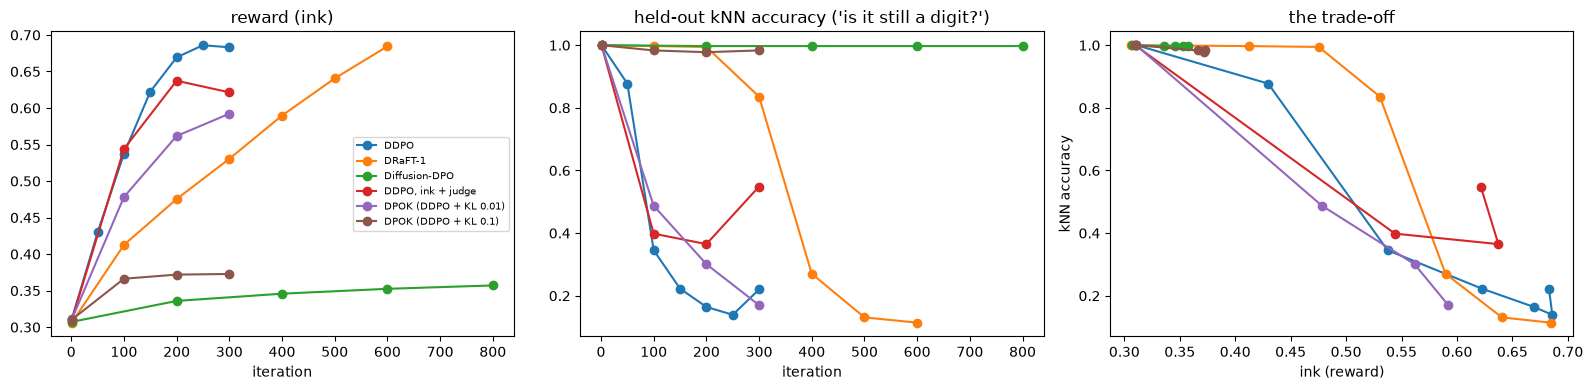

,ink,judge_acc,knn_acc,fd_to_bold,fd_to_data,diversity
base,0.306,0.994,1.000,256.332,5.823,5.549
DDPO,0.683,0.354,0.220,102.277,321.400,3.308
DRaFT-1,0.684,0.206,0.114,298.265,510.205,4.136
Diffusion-DPO,0.357,0.992,0.997,220.862,12.529,5.469
"DDPO, ink + judge",0.621,0.880,0.549,65.867,223.490,3.875
DPOK (DDPO + KL 0.01),0.592,0.279,0.170,70.183,348.686,2.917
DPOK (DDPO + KL 0.1),0.373,0.992,0.983,242.717,15.028,5.450


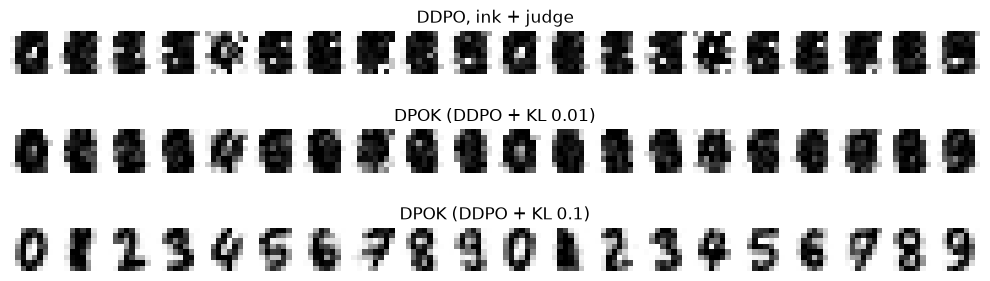

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, h in runs.items():
    h = pd.DataFrame(h).dropna(subset=["knn_acc"])
    x = h["iter"]
    axes[0].plot(x, h.ink, "o-", label=name); axes[1].plot(x, h.knn_acc, "o-"); axes[2].plot(h.ink, h.knn_acc, "o-")
axes[0].set_title("reward (ink)"); axes[0].set_xlabel("iteration"); axes[0].legend(fontsize=7)
axes[1].set_title("held-out kNN accuracy ('is it still a digit?')"); axes[1].set_xlabel("iteration")
axes[2].set_title("the trade-off"); axes[2].set_xlabel("ink (reward)"); axes[2].set_ylabel("kNN accuracy")
fig.tight_layout(); plt.show()
table = pd.DataFrame({"base": base_eval, **{k: evaluate(m) for k, m in models.items()}}).T
display(table.round(3))
fig, axes = plt.subplots(3, 1, figsize=(10, 3.3))
for ax, name in zip(axes, ["DDPO, ink + judge", "DPOK (DDPO + KL 0.01)", "DPOK (DDPO + KL 0.1)"]):
    set_seed(0); images.show_grid(dfx.sample_ddim(models[name], torch.arange(10).repeat(2), steps=20), nrow=20, ax=ax, title=name)
fig.tight_layout(); plt.show()

**What the KL penalty buys.** The right panel is the whole story: each run traces a path from the base model
(little ink, readable) toward more ink, and readability is lost along the way. A KL penalty shortens the path,
since the policy cannot move as far from the pretrained model, so the run ends earlier on the same curve. It does
not change the curve itself, because the reward still does not encode "readable". **Early stopping** is the
other practical tool: every run passes through a point with noticeably more ink and most of its readability
intact. Choosing that point needs a held-out evaluator, which is exactly what labs keep for this purpose.

Recent work replaces this trial and error with principled objectives, for example adjoint matching, which
casts reward fine-tuning of diffusion and flow models as stochastic optimal control ([Domingo-Enrich et al., 2024](https://arxiv.org/abs/2409.08861)).
[Uehara et al., 2024](https://arxiv.org/abs/2407.13734) review the RL view of diffusion fine-tuning in depth.

## 6. Scorecard

In [10]:
rows = [dict(model=k, family="image-aligned", **v) for k, v in table.to_dict("index").items()]
metrics.append_rows(rows, "07_diffusion_alignment")
display(metrics.load_scorecard().query("notebook == '07_diffusion_alignment'")[["model", "ink", "judge_acc", "knn_acc", "fd_to_bold", "fd_to_data"]].round(3))
import os
from ptlib import CKPT_DIR
torch.save(models["Diffusion-DPO"].state_dict(), os.path.join(CKPT_DIR, "diffusion_dpo.pt"))   # used by notebook 08

,model,ink,judge_acc,knn_acc,fd_to_bold,fd_to_data
31,base,0.306,0.994,1.000,256.332,5.823
32,DDPO,0.683,0.354,0.220,102.277,321.400
33,DRaFT-1,0.684,0.206,0.114,298.265,510.205
34,Diffusion-DPO,0.357,0.992,0.997,220.862,12.529
35,"DDPO, ink + judge",0.621,0.880,0.549,65.867,223.490
36,DPOK (DDPO + KL 0.01),0.592,0.279,0.170,70.183,348.686
37,DPOK (DDPO + KL 0.1),0.373,0.992,0.983,242.717,15.028


## Challenge Problem 1: Hack the classifier directly

Use DRaFT-1 with the reward $\log p_\text{judge}(c \mid x)$ only (no ink term), for 300 iterations. Report judge accuracy, kNN accuracy and
FD to the data, and look at the samples. What has the model learned to do, and why is a differentiable reward
especially easy to exploit this way?

In [11]:
# Start your code here

### Challenge Problem 1 Solution

{'ink': 0.315, 'judge_acc': 1.0, 'knn_acc': 1.0, 'fd_to_bold': 263.174, 'fd_to_data': 7.709, 'diversity': 5.521}


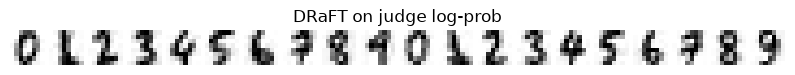

In [12]:
judge_reward = lambda x, c: F.log_softmax(judge(x), -1)[torch.arange(len(c)), c]
m_j, _ = dfx.draft(copy.deepcopy(base), judge_reward, iters=300, lr=2e-5, log_every=0)
print({k: round(v, 3) for k, v in evaluate(m_j).items()})
fig, ax = plt.subplots(figsize=(10, 1.2)); set_seed(0)
images.show_grid(dfx.sample_ddim(m_j, torch.arange(10).repeat(2), steps=20), nrow=20, ax=ax, title="DRaFT on judge log-prob"); plt.show()
# Judge accuracy is already near 1 for the base model, so the reward mostly pushes confidence up. DRaFT follows the
# judge's input gradient, which is exactly how adversarial examples are made: small, structured pixel changes that
# the CNN reads as 'more 3-like'. Compare FD to the data and kNN accuracy to see whether the images changed in
# ways a different evaluator notices.

## Challenge Problem 2: How deep should DRaFT back-propagate?

DRaFT-K back-propagates through the last $K$ sampling steps. Run DRaFT with $K = 1$ and $K = 5$ for 300 iterations each on the
ink reward, and compare reward, kNN accuracy and wall-clock time. Which steps of the sampler control global properties such as
a uniform background?

In [13]:
# Start your code here

### Challenge Problem 2 Solution

In [14]:
for K in [1, 5]:
    t0 = time.time()
    m_k, _ = dfx.draft(copy.deepcopy(base), reward, iters=300, K=K, lr=2e-5, log_every=0)
    print(f"K={K}: {time.time() - t0:.0f}s", {k: round(v, 3) for k, v in evaluate(m_k).items()})
# Gradients through earlier (noisier) steps can change global structure such as stroke layout; the last step mostly
# adjusts pixel intensities. Clark et al. found K=1 already works well and is much cheaper, and that a larger K
# can make optimisation less stable.

K=1: 28s {'ink': 0.533, 'judge_acc': 0.504, 'knn_acc': 0.813, 'fd_to_bold': 270.334, 'fd_to_data': 265.953, 'diversity': 4.915}
K=5: 37s {'ink': 0.989, 'judge_acc': 0.164, 'knn_acc': 0.106, 'fd_to_bold': 278.195, 'fd_to_data': 965.343, 'diversity': 0.791}


## Final summary

* **Adaptation** (DreamBooth, textual inversion, LoRA) teaches a diffusion model a new concept from a few images. Full fine-tuning overfits and drifts. Prior preservation, embedding-only training and LoRA trade expressiveness for stability, as SFT and LoRA did in notebook 02.
* **Reward alignment** ports RLHF to denoisers. The sampling chain is an MDP (DDPO), the sampler is differentiable (DRaFT), and DPO's derivation carries over with denoising errors (Diffusion-DPO).
* Every method found a way to satisfy the letter of the reward. A classifier added to the reward was itself fooled, and only a **held-out evaluator** revealed it. KL penalties and early stopping limit how far a policy can travel, but they don't fix the reward.
* All of this still costs 20+ network evaluations per sample. Notebook 08 distils the sampler.

## References

* Nataniel Ruiz, Yuanzhen Li, Varun Jampani et al. (2022). **DreamBooth: Fine Tuning Text-to-Image Diffusion Models for Subject-Driven Generation**. arXiv:2208.12242. [arxiv.org/abs/2208.12242](https://arxiv.org/abs/2208.12242)
* Rinon Gal, Yuval Alaluf, Yuval Atzmon et al. (2022). **An Image is Worth One Word: Personalizing Text-to-Image Generation using Textual Inversion**. arXiv:2208.01618. [arxiv.org/abs/2208.01618](https://arxiv.org/abs/2208.01618)
* Edward J. Hu, Yelong Shen, Phillip Wallis et al. (2021). **LoRA: Low-Rank Adaptation of Large Language Models**. arXiv:2106.09685. [arxiv.org/abs/2106.09685](https://arxiv.org/abs/2106.09685)
* Lvmin Zhang, Anyi Rao, Maneesh Agrawala (2023). **Adding Conditional Control to Text-to-Image Diffusion Models**. arXiv:2302.05543. [arxiv.org/abs/2302.05543](https://arxiv.org/abs/2302.05543)
* Kevin Black, Michael Janner, Yilun Du et al. (2023). **Training Diffusion Models with Reinforcement Learning**. arXiv:2305.13301. [arxiv.org/abs/2305.13301](https://arxiv.org/abs/2305.13301)
* Ying Fan, Olivia Watkins, Yuqing Du et al. (2023). **DPOK: Reinforcement Learning for Fine-tuning Text-to-Image Diffusion Models**. arXiv:2305.16381. [arxiv.org/abs/2305.16381](https://arxiv.org/abs/2305.16381)
* Kevin Clark, Paul Vicol, Kevin Swersky et al. (2023). **Directly Fine-Tuning Diffusion Models on Differentiable Rewards**. arXiv:2309.17400. [arxiv.org/abs/2309.17400](https://arxiv.org/abs/2309.17400)
* Jiazheng Xu, Xiao Liu, Yuchen Wu et al. (2023). **ImageReward: Learning and Evaluating Human Preferences for Text-to-Image Generation**. arXiv:2304.05977. [arxiv.org/abs/2304.05977](https://arxiv.org/abs/2304.05977)
* Kimin Lee, Hao Liu, Moonkyung Ryu et al. (2023). **Aligning Text-to-Image Models using Human Feedback**. arXiv:2302.12192. [arxiv.org/abs/2302.12192](https://arxiv.org/abs/2302.12192)
* Mihir Prabhudesai, Anirudh Goyal, Deepak Pathak et al. (2023). **Aligning Text-to-Image Diffusion Models with Reward Backpropagation**. arXiv:2310.03739. [arxiv.org/abs/2310.03739](https://arxiv.org/abs/2310.03739)
* Bram Wallace, Meihua Dang, Rafael Rafailov et al. (2023). **Diffusion Model Alignment Using Direct Preference Optimization**. arXiv:2311.12908. [arxiv.org/abs/2311.12908](https://arxiv.org/abs/2311.12908)
* Masatoshi Uehara, Yulai Zhao, Tommaso Biancalani et al. (2024). **Understanding Reinforcement Learning-Based Fine-Tuning of Diffusion Models: A Tutorial and Review**. arXiv:2407.13734. [arxiv.org/abs/2407.13734](https://arxiv.org/abs/2407.13734)
* Carles Domingo-Enrich, Michal Drozdzal, Brian Karrer et al. (2024). **Adjoint Matching: Fine-tuning Flow and Diffusion Generative Models with Memoryless Stochastic Optimal Control**. arXiv:2409.08861. [arxiv.org/abs/2409.08861](https://arxiv.org/abs/2409.08861)

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).